
# Chapter 5
## Learning Multiple Weights at a Time

### Overview

In Chapter 4, we learned how a neural network adjusts a single weight using gradient descent.

In Chapter 5, we extend this idea to networks with multiple inputs and outputs.

We will explore three arrangements:

1. **Multiple inputs → one output:** Several inputs contribute to a single prediction.
2. **One input → multiple outputs:** One input produces several independent predictions.
3. **Multiple inputs → multiple outputs:** Each output combines several inputs using its own weights.

### Key concepts

- **Weighted sum:** Multiplying inputs by their weights and adding the results.
- **Squared error:** Measuring how far predictions are from their targets.
- **Gradient:** Determining how each weight should change to reduce error.
- **Weight matrix:** Organizing multiple weights into rows and columns.

### Learning objective

Understand how gradient descent updates multiple weights, and visualize how prediction errors decrease during training.


In [1]:

# Chapter 5: Multiple inputs, one output

inputs = [0.5, 0.8, 0.2]
weights = [0.2, 0.3, 0.5]

# Multiply each input by its corresponding weight
prediction = 0

for i in range(len(inputs)):
    prediction += inputs[i] * weights[i]

print("Prediction:", prediction)


Prediction: 0.43999999999999995


In [2]:

# Multiple inputs, one output: learning the weights

inputs = [0.5, 0.8, 0.2]
weights = [0.2, 0.3, 0.5]

target = 0.8
alpha = 0.1  # Learning rate

for iteration in range(20):

    # Calculate prediction
    prediction = sum(inputs[i] * weights[i] for i in range(3))

    # Calculate error
    error = (prediction - target) ** 2

    # Calculate gradients
    delta = prediction - target
    gradients = [delta * inputs[i] for i in range(3)]

    print(f"{iteration:2d}: prediction={prediction:.4f}, error={error:.6f}")

    # Update all three weights
    for i in range(3):
        weights[i] -= alpha * gradients[i]

print("\nFinal weights:", weights)


 0: prediction=0.4400, error=0.129600
 1: prediction=0.4735, error=0.106615
 2: prediction=0.5038, error=0.087707
 3: prediction=0.5314, error=0.072152
 4: prediction=0.5564, error=0.059356
 5: prediction=0.5790, error=0.048829
 6: prediction=0.5996, error=0.040169
 7: prediction=0.6182, error=0.033045
 8: prediction=0.6351, error=0.027185
 9: prediction=0.6505, error=0.022363
10: prediction=0.6644, error=0.018397
11: prediction=0.6770, error=0.015134
12: prediction=0.6884, error=0.012450
13: prediction=0.6988, error=0.010242
14: prediction=0.7082, error=0.008426
15: prediction=0.7167, error=0.006931
16: prediction=0.7245, error=0.005702
17: prediction=0.7315, error=0.004691
18: prediction=0.7379, error=0.003859
19: prediction=0.7437, error=0.003175

Final weights: [0.36607353914038365, 0.5657176626246139, 0.5664294156561536]


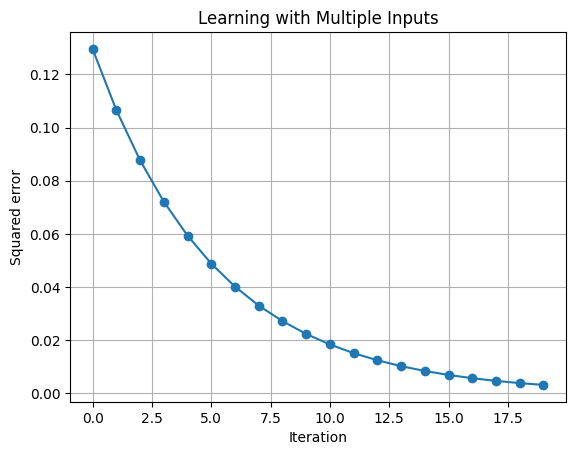

In [3]:

import matplotlib.pyplot as plt

inputs = [0.5, 0.8, 0.2]
weights = [0.2, 0.3, 0.5]
target = 0.8
alpha = 0.1

errors = []

for iteration in range(20):
    prediction = sum(inputs[i] * weights[i] for i in range(3))
    error = (prediction - target) ** 2
    errors.append(error)

    delta = prediction - target
    gradients = [delta * inputs[i] for i in range(3)]

    for i in range(3):
        weights[i] -= alpha * gradients[i]

plt.plot(errors, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Squared error")
plt.title("Learning with Multiple Inputs")
plt.grid(True)
plt.show()


In [4]:

# Chapter 5: One input, multiple outputs

input_value = 0.5
weights = [0.2, 0.3, 0.5]
targets = [0.8, 0.2, 0.3]

alpha = 0.1

for iteration in range(20):

    # Calculate three predictions
    predictions = [input_value * w for w in weights]

    # Calculate three squared errors
    errors = [
        (predictions[i] - targets[i]) ** 2
        for i in range(3)
    ]

    # Calculate three gradients
    gradients = [
        (predictions[i] - targets[i]) * input_value
        for i in range(3)
    ]

    print(f"{iteration:2d}: predictions={predictions}, total error={sum(errors):.6f}")

    # Update each weight
    for i in range(3):
        weights[i] -= alpha * gradients[i]

print("\nFinal weights:", weights)


 0: predictions=[0.1, 0.15, 0.25], total error=0.495000
 1: predictions=[0.11750000000000001, 0.15125, 0.25125], total error=0.470559
 2: predictions=[0.1345625, 0.15246875, 0.25246874999999996], total error=0.447326
 3: predictions=[0.1511984375, 0.15365703125, 0.25365703124999994], total error=0.425239
 4: predictions=[0.1674184765625, 0.15481560546875, 0.25481560546874993], total error=0.404243
 5: predictions=[0.1832330146484375, 0.15594521533203126, 0.2559452153320312], total error=0.384283
 6: predictions=[0.19865218928222655, 0.15704658494873047, 0.2570465849487304], total error=0.365309
 7: predictions=[0.2136858845501709, 0.15812042032501222, 0.25812042032501215], total error=0.347272
 8: predictions=[0.22834373743641662, 0.15916740981688693, 0.25916740981688685], total error=0.330125
 9: predictions=[0.2426351440005062, 0.16018822457146475, 0.2601882245714647], total error=0.313826
10: predictions=[0.2565692654004936, 0.16118351895717814, 0.26118351895717806], total error=0.2

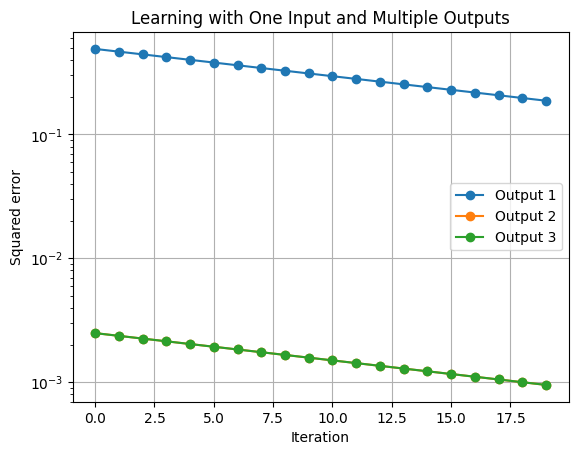

In [6]:

# One input, multiple outputs: visualizing learning

input_value = 0.5
weights = [0.2, 0.3, 0.5]
targets = [0.8, 0.2, 0.3]
alpha = 0.1

error_history = [[], [], []]

for iteration in range(20):
    predictions = [input_value * w for w in weights]

    for i in range(3):
        error = (predictions[i] - targets[i]) ** 2
        error_history[i].append(error)

        gradient = (predictions[i] - targets[i]) * input_value
        weights[i] -= alpha * gradient

# Plot each output's error
for i in range(3):
    plt.plot(error_history[i], marker="o", label=f"Output {i+1}")

plt.xlabel("Iteration")
plt.ylabel("Squared error")
plt.title("Learning with One Input and Multiple Outputs")
plt.legend()
plt.grid(True)
plt.yscale("log")
plt.show()


In [7]:

# Chapter 5: Multiple inputs, multiple outputs

inputs = [0.5, 0.8]

# Each row contains the weights for one output
weights = [
    [0.2, 0.3],
    [0.4, 0.5]
]

targets = [0.8, 0.4]
alpha = 0.1

for iteration in range(20):

    # Calculate both predictions
    predictions = [
        sum(inputs[j] * weights[i][j] for j in range(2))
        for i in range(2)
    ]

    # Calculate squared errors
    errors = [
        (predictions[i] - targets[i]) ** 2
        for i in range(2)
    ]

    # Calculate gradients for all four weights
    gradients = [
        [
            (predictions[i] - targets[i]) * inputs[j]
            for j in range(2)
        ]
        for i in range(2)
    ]

    print(
        f"{iteration:2d}: predictions={predictions}, "
        f"total error={sum(errors):.6f}"
    )

    # Update all four weights
    for i in range(2):
        for j in range(2):
            weights[i][j] -= alpha * gradients[i][j]

print("\nFinal weights:", weights)


 0: predictions=[0.33999999999999997, 0.6000000000000001], total error=0.251600
 1: predictions=[0.38094000000000006, 0.5822], total error=0.208808
 2: predictions=[0.41823634, 0.5659842], total error=0.173294
 3: predictions=[0.45221330574, 0.5512116062], total error=0.143821
 4: predictions=[0.4831663215291401, 0.5377537732482001], total error=0.119360
 5: predictions=[0.5113645189130466, 0.5254936874291102], total error=0.099059
 6: predictions=[0.5370530767297854, 0.5143247492479194], total error=0.082211
 7: predictions=[0.5604553529008345, 0.5041498465648546], total error=0.068229
 8: predictions=[0.5817748264926602, 0.49488051022058244], total error=0.056625
 9: predictions=[0.6011968669348136, 0.48643614481095065], total error=0.046994
10: predictions=[0.6188903457776151, 0.478743327922776], total error=0.039001
11: predictions=[0.6350091050034073, 0.4717351717376489], total error=0.032368
12: predictions=[0.6496932946581041, 0.4653507414529982], total error=0.026863
13: predic